In [1]:
# Memasang pustaka tambahan (-q artinya tampil singkat)
%pip -q install tensorflow-datasets scikit-learn seaborn gradio

# Memanggil pustaka yang akan dipakai
import os, json, random, shutil, time, gc
from pathlib import Path
import numpy as np                      # hitungan angka
import pandas as pd                     # tabel data
import matplotlib.pyplot as plt         # membuat grafik
import seaborn as sns                   # grafik tambahan
from PIL import Image                   # membuka gambar
import tensorflow as tf                 # mesin deep learning
import tensorflow_datasets as tfds      # pengunduh dataset
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix)

# Seed: angka tetap supaya hasil acak selalu sama setiap dijalankan
SEED = 42
keras.utils.set_random_seed(SEED)

# Cek versi dan GPU
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('TFDS:', tfds.__version__)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TFDS: 4.9.10


In [2]:
# False = simpan di Colab sementara. Ganti True kalau mau simpan otomatis ke Google Drive
USE_GOOGLE_DRIVE = False
ROOT = Path('/content/SDG2_Cassava')   # folder utama project

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        ROOT = Path('/content/drive/MyDrive/SDG2_Cassava')
    except Exception as err:
        print('Drive gagal; lanjut di /content:', str(err)[:150])

# Subfolder untuk tiap jenis hasil
DATA_DIR = Path('/content/tfds_cassava')
MODELS_DIR = ROOT / 'models'
PLOTS_DIR = ROOT / 'plots'
REPORT_DIR = ROOT / 'reports'
APP_DIR = ROOT / 'app_artifacts'

# Membuat semua folder (kalau sudah ada, tidak error)
for folder in [ROOT, DATA_DIR, MODELS_DIR, PLOTS_DIR, REPORT_DIR, APP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print('Folder proyek:', ROOT)

Folder proyek: /content/SDG2_Cassava


In [3]:
# Install importlib_resources to fix the ModuleNotFoundError
%pip install -q importlib_resources

# Mengunduh dataset iCassava 2019 dan langsung membaginya menjadi 3 bagian
(raw_train, raw_val, raw_test), info = tfds.load(
    'cassava',
    split=['train', 'validation', 'test'],
    as_supervised=True,        # data berbentuk pasangan (gambar, label)
    with_info=True,            # ikut ambil info dataset
    data_dir=str(DATA_DIR),
    download=True,
    shuffle_files=False
)

# Nama kelas diambil dari dataset, bukan ditebak
RAW_LABELS = list(info.features['label'].names)

# Nama lengkap untuk tampilan
PRETTY = {
    'cbb': 'Cassava Bacterial Blight (CBB)',
    'cbsd': 'Cassava Brown Streak Disease (CBSD)',
    'cgm': 'Cassava Green Mite (CGM)',
    'cmd': 'Cassava Mosaic Disease (CMD)',
    'healthy': 'Healthy'
}
CLASS_NAMES = [PRETTY.get(name.lower(), name) for name in RAW_LABELS]
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == 5   # berhenti dengan error kalau jumlah kelas bukan 5

print('Label TFDS:', RAW_LABELS)
print('Train:', info.splits['train'].num_examples)
print('Validation:', info.splits['validation'].num_examples)
print('Test:', info.splits['test'].num_examples)

# Pengecekan jumlah gambar sesuai dataset resmi
assert (info.splits['train'].num_examples,
        info.splits['validation'].num_examples,
        info.splits['test'].num_examples) == (5656, 1889, 1885)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tfds_cassava/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tfds_cassava/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9][0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tfds_cassava/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9][0-…

Dataset cassava downloaded and prepared to /content/tfds_cassava/cassava/0.1.0. Subsequent calls will reuse this data.
Label TFDS: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Train: 5656
Validation: 1889
Test: 1885


  kelas  train  validation  test
    cbb    466         156   155
   cbsd   1443         482   481
    cgm    773         258   258
    cmd   2658         887   886
healthy    316         106   105


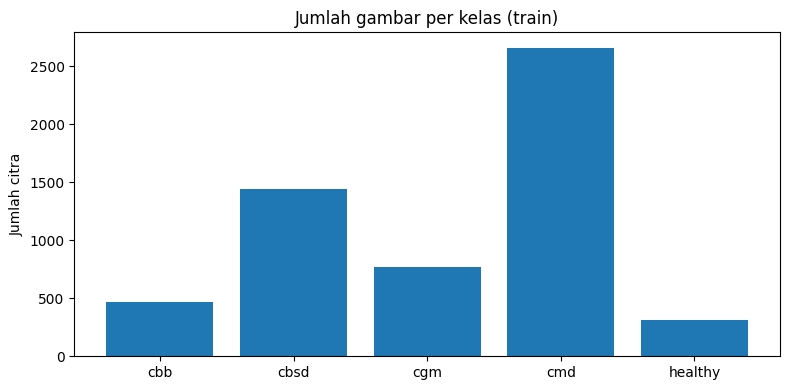

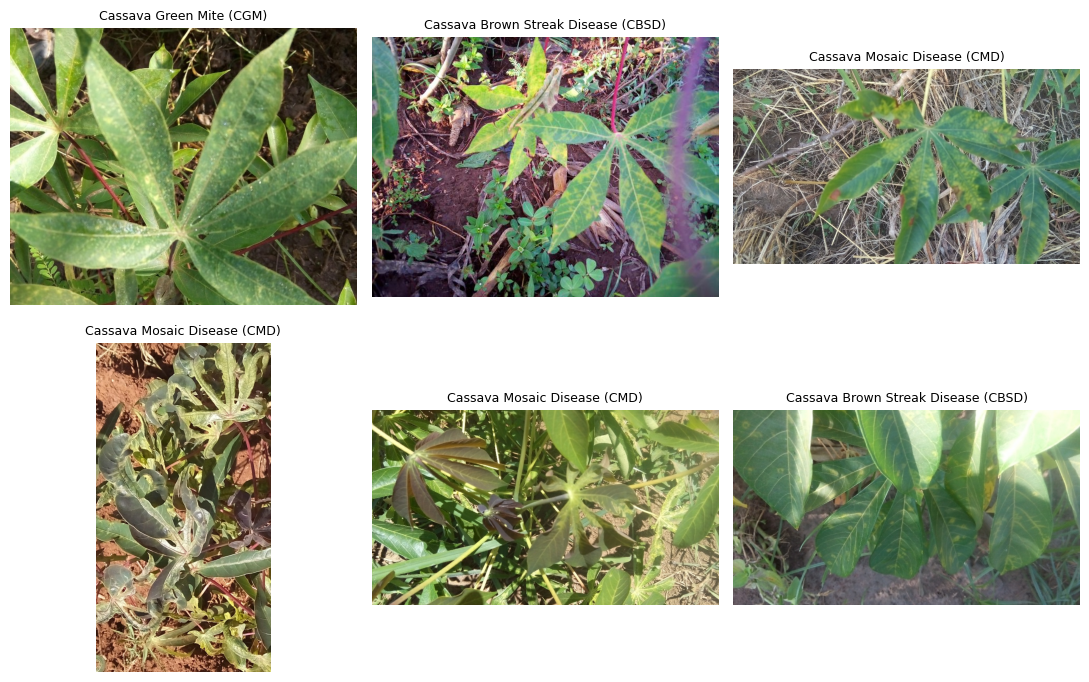

In [4]:
# Fungsi untuk menghitung berapa gambar di tiap kelas
def label_counts(raw_ds):
    counts = np.zeros(NUM_CLASSES, dtype=np.int64)       # 5 kotak berisi angka 0
    labels_only = raw_ds.map(lambda image, label: label) # ambil label saja
    for batch in labels_only.batch(256):                 # baca per 256 data
        counts += np.bincount(batch.numpy(), minlength=NUM_CLASSES)
    return counts

TRAIN_COUNTS = label_counts(raw_train)
VAL_COUNTS = label_counts(raw_val)
TEST_COUNTS = label_counts(raw_test)

# Susun jadi tabel
dist = pd.DataFrame({
    'kelas': RAW_LABELS,
    'train': TRAIN_COUNTS,
    'validation': VAL_COUNTS,
    'test': TEST_COUNTS
})
print(dist.to_string(index=False))
dist.to_csv(REPORT_DIR / 'distribusi_kelas.csv', index=False)

# Grafik batang jumlah gambar per kelas (data train)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(RAW_LABELS, TRAIN_COUNTS)
ax.set(title='Jumlah gambar per kelas (train)', ylabel='Jumlah citra')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'eda_distribusi.png', dpi=160)
plt.show()

# Tampilkan 6 contoh foto acak
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, (image, y) in zip(axes.flat, raw_train.shuffle(200, seed=SEED).take(6)):
    ax.imshow(image.numpy())
    ax.set_title(CLASS_NAMES[int(y.numpy())], fontsize=9)
    ax.axis('off')
for ax in axes.flat[6:]: ax.axis('off')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'eda_contoh.png', dpi=160)
plt.show()

In [5]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32          # kalau memori habis (OOM), ganti jadi 16
AUTOTUNE = tf.data.AUTOTUNE

# Mengubah tiap gambar jadi 224x224 dan label jadi angka bulat
def prepare(image, label):
    image = tf.image.resize_with_pad(
        tf.cast(image, tf.float32), IMG_SIZE[0], IMG_SIZE[1])
    return image, tf.cast(label, tf.int32)

# Membuat jalur data siap pakai
def make_dataset(raw_ds, training=False):
    ds = raw_ds
    if training:
        ds = ds.shuffle(1000, seed=SEED, reshuffle_each_iteration=True)  # acak urutan
    ds = ds.map(prepare, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(raw_train, training=True)
val_ds = make_dataset(raw_val)      # validation tidak diacak
test_ds = make_dataset(raw_test)    # test tidak diacak

# Cek satu batch
for x, y in train_ds.take(1):
    print('Batch:', x.shape, y.shape)
    print('Pixel min/max:', float(tf.reduce_min(x)), float(tf.reduce_max(x)))

Batch: (32, 224, 224, 3) (32,)
Pixel min/max: 0.0 255.0


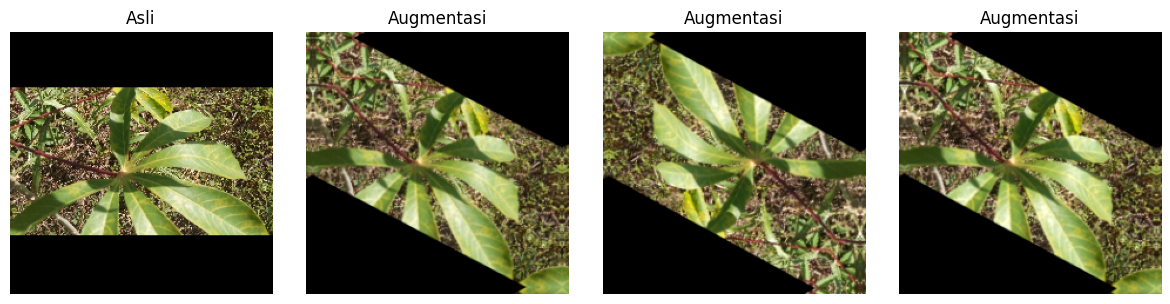

In [6]:
# Daftar perubahan acak yang akan diterapkan pada foto training
def augmenter():
    return keras.Sequential([
        layers.RandomFlip('horizontal_and_vertical'),  # dibalik kiri-kanan / atas-bawah
        layers.RandomRotation(0.08),                   # diputar sedikit
        layers.RandomZoom(0.10),                       # di-zoom sedikit
        layers.RandomContrast(0.10),                   # kontras diubah sedikit
    ], name='augmenter')

# Contoh: ambil satu foto, lihat 3 versi hasil augmentasinya
example = next(iter(train_ds))[0][0]
aug = augmenter()

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(tf.cast(example, tf.uint8))
axes[0].set_title('Asli')
for i in range(1, 4):
    changed = aug(example[None, ...], training=True)[0]
    axes[i].imshow(tf.cast(tf.clip_by_value(changed, 0, 255), tf.uint8))
    axes[i].set_title('Augmentasi')
for ax in axes: ax.axis('off')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'contoh_augmentasi.png', dpi=160)
plt.show()

In [7]:
# Menyiapkan model: loss, optimizer, dan metrik
def compile_classifier(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
    )

# Tiga "penjaga" yang bekerja saat pelatihan
def callbacks(key):
    return [
        # 1. Simpan model terbaik (val_loss paling kecil)
        keras.callbacks.ModelCheckpoint(
            str(MODELS_DIR / f'{key}.keras'),
            monitor='val_loss', mode='min', save_best_only=True),
        # 2. Berhenti lebih awal kalau 3 epoch tidak membaik
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True),
        # 3. Kecilkan learning rate kalau macet 2 epoch
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7)
    ]

# Menjalankan pelatihan lalu menyimpan riwayatnya ke CSV
def fit_save(model, key, epochs, class_weight=None):
    hist = model.fit(
        train_ds, validation_data=val_ds,
        epochs=epochs, callbacks=callbacks(key),
        class_weight=class_weight, verbose=1)
    pd.DataFrame(hist.history).to_csv(
        REPORT_DIR / f'history_{key}.csv', index=False)
    return hist

# Saklar: ubah ke False hanya kalau checkpoint-nya sudah tersimpan
RUN_CNN = True
RUN_TRANSFER = True
RUN_FINE_TUNE = True
RUN_WEIGHTED = True

In [8]:
def build_custom_cnn():
    inp = keras.Input(shape=(224, 224, 3), name='image')
    x = augmenter()(inp)                       # augmentasi (aktif saat latihan saja)
    x = layers.Rescaling(1.0 / 255.0)(x)       # ubah piksel 0-255 jadi 0-1
    # Tiga blok: konvolusi (cari pola) + pooling (ringkas)
    for i, filters in enumerate((32, 64, 128), start=1):
        x = layers.Conv2D(filters, 3, padding='same',
                          activation='relu', name=f'conv_{i}')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D(name='pool')(x)   # ringkas jadi satu deret angka
    x = layers.Dropout(0.30, name='classifier_dropout')(x)  # cegah menghafal
    logits = layers.Dense(NUM_CLASSES, name='classifier_logits')(x)  # skor 5 kelas
    out = layers.Activation('softmax', name='probabilities')(logits) # jadi peluang
    return keras.Model(inp, out, name='Cassava_CustomCNN')

if RUN_CNN:
    keras.utils.set_random_seed(SEED)
    cnn = build_custom_cnn()
    compile_classifier(cnn, learning_rate=1e-3)
    hist_cnn = fit_save(cnn, 'custom_cnn', epochs=12)
    del cnn
    gc.collect()

Epoch 1/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 36s 154ms/step - accuracy: 0.4653 - loss: 1.3401 - val_accuracy: 0.4696 - val_loss: 1.2909 - learning_rate: 0.0010
Epoch 2/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 27s 140ms/step - accuracy: 0.4853 - loss: 1.2850 - val_accuracy: 0.4865 - val_loss: 1.2500 - learning_rate: 0.0010
Epoch 3/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 40s 136ms/step - accuracy: 0.5428 - loss: 1.2205 - val_accuracy: 0.5659 - val_loss: 1.1803 - learning_rate: 0.0010
Epoch 4/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 26s 134ms/step - accuracy: 0.5573 - loss: 1.1898 - val_accuracy: 0.5161 - val_loss: 1.2443 - learning_rate: 0.0010
Epoch 5/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 26s 135ms/step - accuracy: 0.5743 - loss: 1.1661 - val_accuracy: 0.6114 - val_loss: 1.1130 - learning_rate: 0.0010
Epoch 6/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 26s 135ms/step - accuracy: 0.5838 - loss: 1.1443 - val_accuracy: 0.5691 - val_loss: 1.1614 - learning_rate: 0.0010
Epoch 7/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 41s 136ms/step - accuracy: 0.5

In [9]:
def build_efficientnet():
    inp = keras.Input(shape=(224, 224, 3), name='image')
    x = augmenter()(inp)                          # augmentasi (aktif saat latihan saja)

    # Backbone EfficientNetB0 dengan bobot ImageNet
    backbone = keras.applications.EfficientNetB0(
        include_top=False, weights='imagenet',
        input_shape=(224, 224, 3))
    backbone.trainable = False                    # bekukan backbone

    features = backbone(x, training=False)        # ambil fitur gambar
    x = layers.GlobalAveragePooling2D(name='pool')(features)
    x = layers.Dropout(0.30, name='classifier_dropout')(x)
    logits = layers.Dense(NUM_CLASSES, name='classifier_logits')(x)   # head: 5 kelas
    out = layers.Activation('softmax', name='probabilities')(logits)
    return keras.Model(inp, out, name='Cassava_EfficientNetB0')

if RUN_TRANSFER:
    keras.utils.set_random_seed(SEED)
    transfer = build_efficientnet()
    compile_classifier(transfer, learning_rate=1e-3)
    hist_transfer = fit_save(transfer, 'efficientnet_frozen', epochs=10)
    del transfer
    gc.collect()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 43s 171ms/step - accuracy: 0.6087 - loss: 1.0270 - val_accuracy: 0.6681 - val_loss: 0.8925 - learning_rate: 0.0010
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 32s 170ms/step - accuracy: 0.6909 - loss: 0.8417 - val_accuracy: 0.6930 - val_loss: 0.8186 - learning_rate: 0.0010
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 31s 157ms/step - accuracy: 0.7125 - loss: 0.8007 - val_accuracy: 0.7152 - val_loss: 0.7860 - learning_rate: 0.0010
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 28s 147ms/step - accuracy: 0.7247 - loss: 0.7739 - val_accuracy: 0.6840 - val_loss: 0.8132 - learning_rate: 0.0010
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 28s 146ms/step - accuracy: 0.7263 - loss: 0.7508 - val_accuracy: 0.6935 - val_loss: 0.7861 - learning_rate: 0.0010
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 27s 143ms/step - accuracy: 0.7376 - loss: 0.7350 - val_accuracy: 0.6945 - val_loss: 0.7873 - learning_rate: 5.0000e-04


In [10]:
if RUN_FINE_TUNE:
    # Ambil model B yang sudah dilatih (EfficientNet frozen)
    source = MODELS_DIR / 'efficientnet_frozen.keras'
    assert source.exists(), 'Jalankan eksperimen B terlebih dahulu'
    fine = keras.models.load_model(source)
    base = fine.get_layer('efficientnetb0')   # ambil bagian backbone

    # Mulai dari semua dibekukan
    base.trainable = True
    for layer in base.layers:
        layer.trainable = False

    # Buka 30 lapisan terakhir, kecuali BatchNormalization
    for layer in base.layers[-30:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True

    compile_classifier(fine, learning_rate=1e-5)   # langkah kecil
    print('Layer trainable backbone:',
          sum(int(layer.trainable) for layer in base.layers))

    hist_fine = fit_save(fine, 'efficientnet_finetuned', epochs=6)
    del fine
    gc.collect()

Layer trainable backbone: 23
Epoch 1/6
177/177 ━━━━━━━━━━━━━━━━━━━━ 43s 169ms/step - accuracy: 0.7268 - loss: 0.7638 - val_accuracy: 0.7030 - val_loss: 0.7769 - learning_rate: 1.0000e-05
Epoch 2/6
177/177 ━━━━━━━━━━━━━━━━━━━━ 39s 201ms/step - accuracy: 0.7346 - loss: 0.7375 - val_accuracy: 0.7046 - val_loss: 0.7663 - learning_rate: 1.0000e-05
Epoch 3/6
177/177 ━━━━━━━━━━━━━━━━━━━━ 32s 153ms/step - accuracy: 0.7346 - loss: 0.7316 - val_accuracy: 0.7057 - val_loss: 0.7739 - learning_rate: 1.0000e-05
Epoch 4/6
177/177 ━━━━━━━━━━━━━━━━━━━━ 29s 155ms/step - accuracy: 0.7382 - loss: 0.7253 - val_accuracy: 0.7083 - val_loss: 0.7607 - learning_rate: 1.0000e-05
Epoch 5/6
177/177 ━━━━━━━━━━━━━━━━━━━━ 30s 156ms/step - accuracy: 0.7405 - loss: 0.7133 - val_accuracy: 0.7088 - val_loss: 0.7532 - learning_rate: 1.0000e-05
Epoch 6/6
177/177 ━━━━━━━━━━━━━━━━━━━━ 33s 170ms/step - accuracy: 0.7472 - loss: 0.7000 - val_accuracy: 0.7120 - val_loss: 0.7543 - learning_rate: 1.0000e-05


In [11]:
# Hitung bobot tiap kelas dari jumlah gambar train
CLASS_WEIGHTS = {
    i: float(TRAIN_COUNTS.sum() / (NUM_CLASSES * TRAIN_COUNTS[i]))
    for i in range(NUM_CLASSES)
}
print('Bobot kelas:', CLASS_WEIGHTS)

if RUN_WEIGHTED:
    keras.utils.set_random_seed(SEED)
    weighted = build_efficientnet()                  # model baru (bobot ImageNet)
    compile_classifier(weighted, learning_rate=1e-3)
    hist_weight = fit_save(
        weighted, 'efficientnet_weighted', epochs=10,
        class_weight=CLASS_WEIGHTS)                  # pelatihan dengan bobot kelas
    del weighted
    gc.collect()

Bobot kelas: {0: 2.4274678111587984, 1: 0.7839223839223839, 2: 1.4633893919793015, 3: 0.4255831452219714, 4: 3.579746835443038}
Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 41s 168ms/step - accuracy: 0.5177 - loss: 1.2315 - val_accuracy: 0.4553 - val_loss: 1.2938 - learning_rate: 0.0010
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 29s 152ms/step - accuracy: 0.6183 - loss: 1.0268 - val_accuracy: 0.5199 - val_loss: 1.1716 - learning_rate: 0.0010
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 30s 151ms/step - accuracy: 0.6388 - loss: 0.9632 - val_accuracy: 0.5760 - val_loss: 1.0668 - learning_rate: 0.0010
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 32s 170ms/step - accuracy: 0.6489 - loss: 0.9439 - val_accuracy: 0.5765 - val_loss: 1.0598 - learning_rate: 0.0010
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 28s 146ms/step - accuracy: 0.6639 - loss: 0.9085 - val_accuracy: 0.5712 - val_loss: 1.0716 - learning_rate: 0.0010
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 28s 144ms/step - accuracy: 0.6715 - loss: 0.9020 - val_ac

In [12]:
import zipfile
archive = Path('/content/hasil_SDG2_Cassava.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in (MODELS_DIR, PLOTS_DIR, REPORT_DIR, APP_DIR):
        for path in folder.rglob('*'):
            if path.is_file():
                z.write(path, arcname=path.relative_to(ROOT))
print('ZIP:', archive, 'MB:', round(archive.stat().st_size / 1e6, 1))

from google.colab import files
files.download(str(archive))

ZIP: /content/hasil_SDG2_Cassava.zip MB: 61.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

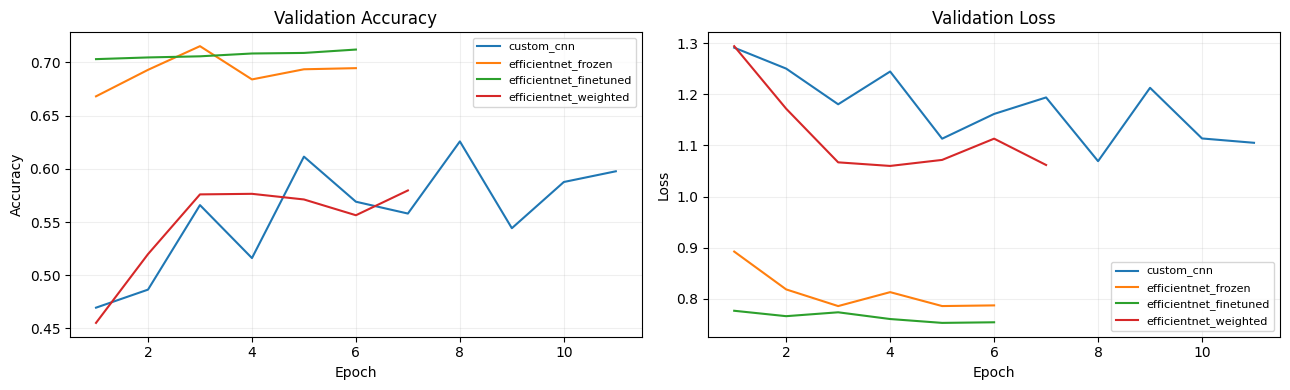

In [13]:
KEYS = ['custom_cnn', 'efficientnet_frozen',
        'efficientnet_finetuned', 'efficientnet_weighted']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key in KEYS:
    path = REPORT_DIR / f'history_{key}.csv'
    if not path.exists(): continue
    history = pd.read_csv(path)                       # baca riwayat latihan
    ep = np.arange(1, len(history) + 1)
    axes[0].plot(ep, history['val_accuracy'], label=key)
    axes[1].plot(ep, history['val_loss'], label=key)

axes[0].set(title='Validation Accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[1].set(title='Validation Loss', xlabel='Epoch', ylabel='Loss')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'learning_curves.png', dpi=180)
plt.show()

In [14]:
# Fungsi: model menebak seluruh dataset, lalu kembalikan jawaban benar & tebakan
def dataset_predictions(model, dataset):
    probs = model.predict(dataset, verbose=0)
    true = np.concatenate([y.numpy() for _, y in dataset])
    pred = probs.argmax(axis=1)
    assert len(probs) == len(true)
    return true, pred, probs

rows = []
for key in KEYS:
    p = MODELS_DIR / f'{key}.keras'
    if not p.exists(): continue
    model = keras.models.load_model(p)
    true, pred, _ = dataset_predictions(model, val_ds)
    rows.append({
        'model': key,
        'val_accuracy': accuracy_score(true, pred),
        'val_macro_f1': f1_score(true, pred, average='macro',
                                 labels=list(range(NUM_CLASSES)), zero_division=0),
        'val_balanced_accuracy': balanced_accuracy_score(true, pred)
    })
    del model
    gc.collect()

assert rows, 'Latih setidaknya satu model sebelum evaluasi'
comparison = pd.DataFrame(rows).sort_values('val_macro_f1', ascending=False)
comparison.to_csv(REPORT_DIR / 'perbandingan_validation.csv', index=False)
print(comparison.to_string(index=False))

BEST_KEY = comparison.iloc[0]['model']
print('Model terpilih:', BEST_KEY)

                 model  val_accuracy  val_macro_f1  val_balanced_accuracy
   efficientnet_frozen      0.715193      0.631918               0.643032
efficientnet_finetuned      0.708841      0.620603               0.646239
 efficientnet_weighted      0.576496      0.498040               0.628716
            custom_cnn      0.625728      0.367679               0.389940
Model terpilih: efficientnet_frozen


{'selected_model': 'efficientnet_frozen', 'test_accuracy': 0.7209549071618037, 'test_macro_f1': 0.6360466250948871, 'test_balanced_accuracy': 0.6652728715596126}
                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)       0.39      0.64      0.48       155
Cassava Brown Streak Disease (CBSD)       0.78      0.54      0.64       481
           Cassava Green Mite (CGM)       0.66      0.58      0.62       258
       Cassava Mosaic Disease (CMD)       0.84      0.88      0.86       886
                            Healthy       0.51      0.69      0.58       105

                           accuracy                           0.72      1885
                          macro avg       0.63      0.67      0.64      1885
                       weighted avg       0.74      0.72      0.72      1885



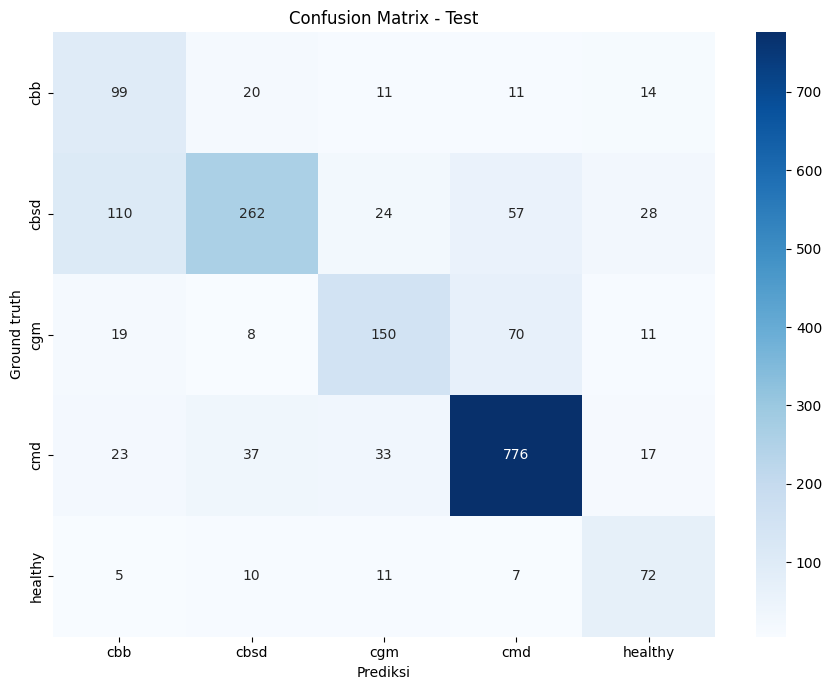

171

In [15]:
# Muat model terpilih dan uji pada data TEST
best_model = keras.models.load_model(MODELS_DIR / f'{BEST_KEY}.keras')
y_true, y_pred, y_prob = dataset_predictions(best_model, test_ds)

final_scores = {
    'selected_model': BEST_KEY,
    'test_accuracy': float(accuracy_score(y_true, y_pred)),
    'test_macro_f1': float(f1_score(
        y_true, y_pred, average='macro',
        labels=list(range(NUM_CLASSES)), zero_division=0)),
    'test_balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred))
}
print(final_scores)

# Tabel nilai per kelas
report = classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES, zero_division=0)
print(report)
(REPORT_DIR / 'classification_report_test.txt').write_text(report)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=RAW_LABELS, yticklabels=RAW_LABELS, ax=ax)
ax.set(xlabel='Prediksi', ylabel='Ground truth', title='Confusion Matrix - Test')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'confusion_matrix_test.png', dpi=180)
plt.show()

# Simpan hasil ke file
pd.DataFrame({'true': y_true, 'pred': y_pred,
              'max_softmax': y_prob.max(axis=1)}).to_csv(
    REPORT_DIR / 'prediksi_test.csv', index=False)
(REPORT_DIR / 'hasil_akhir.json').write_text(
    json.dumps(final_scores, indent=2), encoding='utf-8')

In [16]:
robust_subset = test_ds.take(12)    # 12 batch pertama dari data test

# Mengubah kondisi foto
def perturb(batch_images, mode):
    if mode == 'gelap':
        batch_images = tf.image.adjust_brightness(batch_images, -35.0)
    elif mode == 'terang':
        batch_images = tf.image.adjust_brightness(batch_images, 35.0)
    elif mode == 'kontras_rendah':
        batch_images = tf.image.adjust_contrast(batch_images, 0.65)
    return tf.clip_by_value(batch_images, 0, 255)

robust_rows = []
for condition in ['normal', 'gelap', 'terang', 'kontras_rendah']:
    altered = robust_subset.map(
        lambda images, labels: (perturb(images, condition), labels))
    true, pred, _ = dataset_predictions(best_model, altered)
    robust_rows.append({
        'kondisi': condition,
        'accuracy': accuracy_score(true, pred),
        'macro_f1': f1_score(true, pred, average='macro',
                             labels=list(range(NUM_CLASSES)), zero_division=0)
    })

robust_df = pd.DataFrame(robust_rows)
print(robust_df.to_string(index=False))
robust_df.to_csv(REPORT_DIR / 'robustness.csv', index=False)

       kondisi  accuracy  macro_f1
        normal  0.729167  0.639872
         gelap  0.708333  0.628619
        terang  0.723958  0.645749
kontras_rendah  0.718750  0.626828


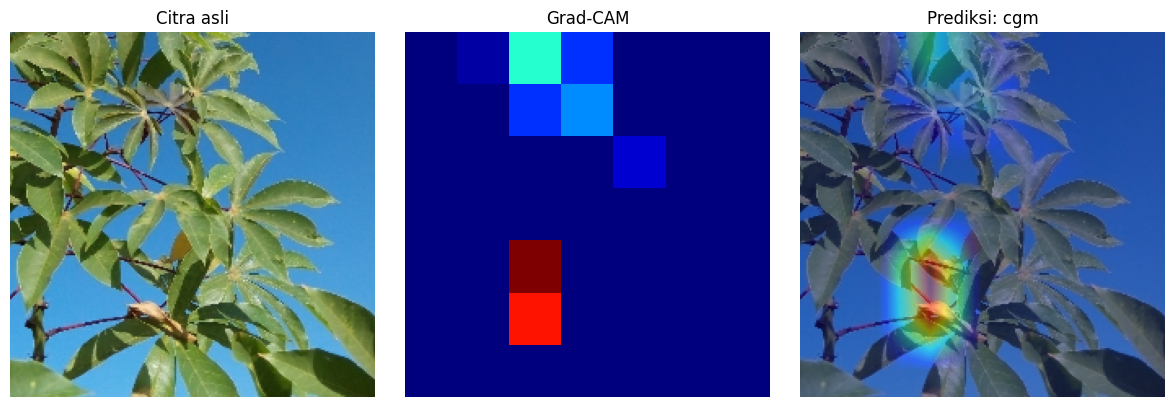

In [17]:
# Membuat heatmap Grad-CAM untuk satu foto
def get_gradcam_heatmap(model, batch):
    batch = tf.convert_to_tensor(batch, dtype=tf.float32)

    if any(layer.name == 'efficientnetb0' for layer in model.layers):
        # Model EfficientNet: ambil lapisan 'top_conv' di dalam backbone
        base = model.get_layer('efficientnetb0')
        probe = keras.Model(base.inputs, [
            base.get_layer('top_conv').output, base.output])
        with tf.GradientTape() as tape:
            x = model.get_layer('augmenter')(batch, training=False)
            fmap, features = probe(x, training=False)
            pooled = model.get_layer('pool')(features)
            pooled = model.get_layer('classifier_dropout')(pooled, training=False)
            logits = model.get_layer('classifier_logits')(pooled)
            class_idx = tf.argmax(logits[0])
            score = tf.gather(logits[0], class_idx)
        grads = tape.gradient(score, fmap)
    else:
        # Model CNN dasar: pakai lapisan 'conv_3'
        probe = keras.Model(model.inputs, [
            model.get_layer('conv_3').output,
            model.get_layer('classifier_logits').output])
        with tf.GradientTape() as tape:
            fmap, logits = probe(batch, training=False)
            class_idx = tf.argmax(logits[0])
            score = tf.gather(logits[0], class_idx)
        grads = tape.gradient(score, fmap)

    if grads is None:
        raise RuntimeError('Grad-CAM: gradient None, cek arsitektur model')

    weights = tf.reduce_mean(grads, axis=(1, 2))[0]   # bobot tiap saluran
    heat = tf.reduce_sum(fmap[0] * weights, axis=-1)  # gabungkan jadi satu peta
    heat = tf.nn.relu(heat)                           # buang nilai negatif
    heat = heat / (tf.reduce_max(heat) + 1e-8)        # skala 0 sampai 1
    return heat.numpy(), int(class_idx.numpy())

# Menempelkan heatmap berwarna di atas foto asli
def overlay_gradcam(image_224, heatmap, alpha=0.40):
    original = np.clip(image_224, 0, 255).astype('uint8')
    resized = tf.image.resize(heatmap[..., None], IMG_SIZE).numpy()[..., 0]
    colors = (plt.get_cmap('jet')(resized)[..., :3] * 255).astype('uint8')
    return ((1 - alpha) * original.astype(float) +
            alpha * colors.astype(float)).astype('uint8')

# Contoh: satu foto dari data test
sample_x, sample_y = next(iter(test_ds))
heatmap, guess = get_gradcam_heatmap(best_model, sample_x[:1])
overlay = overlay_gradcam(sample_x[0].numpy(), heatmap)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(sample_x[0].numpy().astype('uint8'))
axes[0].set_title('Citra asli')
axes[1].imshow(heatmap, cmap='jet')
axes[1].set_title('Grad-CAM')
axes[2].imshow(overlay)
axes[2].set_title('Prediksi: ' + RAW_LABELS[guess])
for ax in axes: ax.axis('off')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'gradcam_contoh.png', dpi=180)
plt.show()

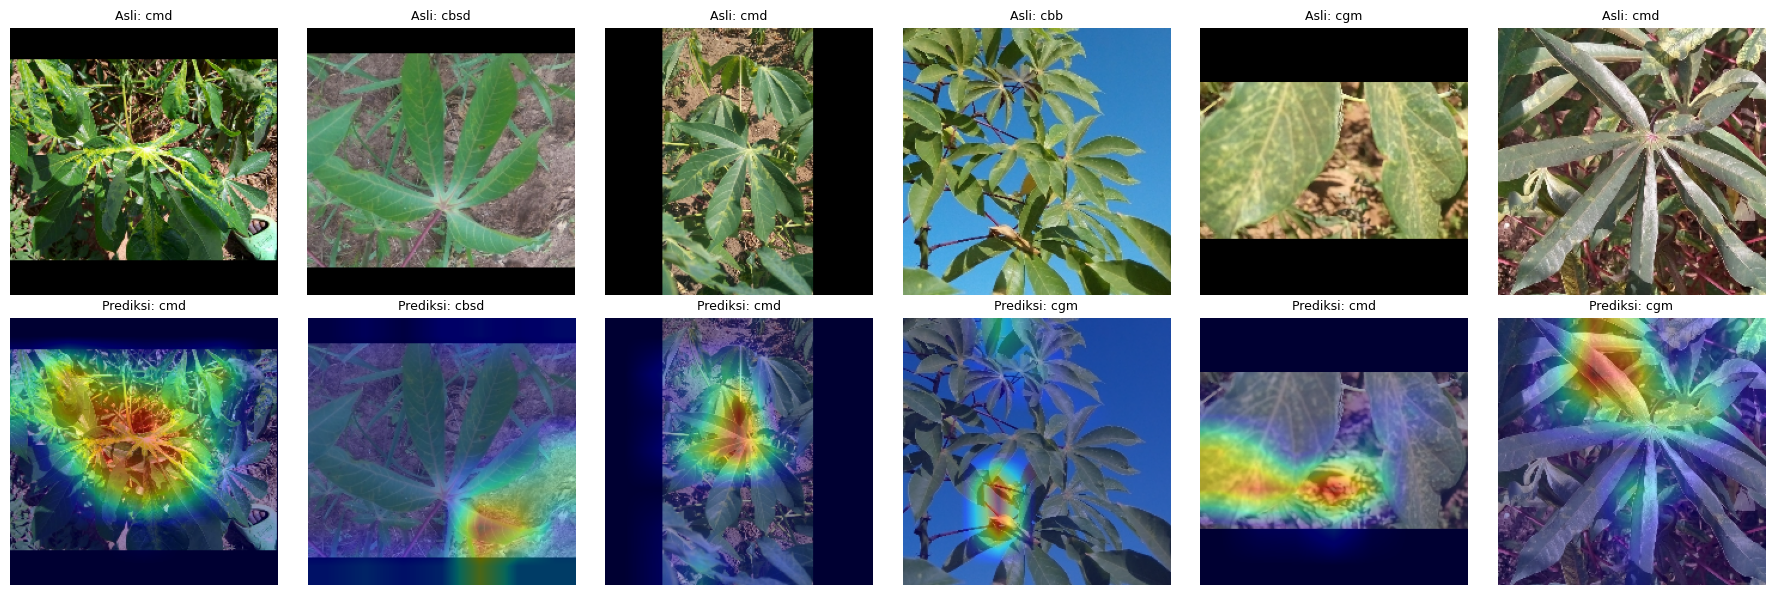

In [18]:
# Kumpulkan 3 contoh tebakan benar dan 3 contoh tebakan salah dari data test
correct, wrong = [], []
offset = 0
for xb, yb in test_ds:
    for i in range(len(yb)):
        idx = offset + i
        item = (xb[i].numpy(), int(y_true[idx]), int(y_pred[idx]))
        if y_true[idx] == y_pred[idx] and len(correct) < 3:
            correct.append(item)
        elif y_true[idx] != y_pred[idx] and len(wrong) < 3:
            wrong.append(item)
    offset += len(yb)
    if len(correct) == 3 and len(wrong) == 3:
        break

items = correct + wrong
fig, axes = plt.subplots(2, len(items), figsize=(3 * len(items), 6))
for col, (img, t, p) in enumerate(items):
    heat, _ = get_gradcam_heatmap(best_model, img[None, ...])
    axes[0, col].imshow(img.astype('uint8'))
    axes[0, col].set_title(f'Asli: {RAW_LABELS[t]}', fontsize=9)
    axes[1, col].imshow(overlay_gradcam(img, heat))
    axes[1, col].set_title(f'Prediksi: {RAW_LABELS[p]}', fontsize=9)
for ax in axes.flat: ax.axis('off')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'gradcam_benar_salah.png', dpi=180)
plt.show()

In [19]:
# Salin model terbaik dan simpan daftar nama kelas untuk aplikasi
shutil.copy2(MODELS_DIR / f'{BEST_KEY}.keras', APP_DIR / 'best_model.keras')
(APP_DIR / 'class_names.json').write_text(
    json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding='utf-8')
(APP_DIR / 'metadata.json').write_text(json.dumps({
    'dataset': 'tfds/cassava (iCassava 2019)',
    'best_model': BEST_KEY,
    'image_size': list(IMG_SIZE),
    'pixel_range': '[0, 255]',
    'source_splits': ['train', 'validation', 'test'],
    'seed': SEED,
    'scores': final_scores
}, ensure_ascii=False, indent=2), encoding='utf-8')
print('Artefak tersimpan:', APP_DIR)

Artefak tersimpan: /content/SDG2_Cassava/app_artifacts


In [20]:
import gradio as gr

# Fungsi yang dijalankan saat tombol ditekan
def classify_leaf(pil_image):
    if pil_image is None:
        return {}, None, 'Unggah foto daun terlebih dahulu.'
    # Samakan preprocessing dengan saat latihan
    arr = np.asarray(pil_image.convert('RGB'), dtype=np.float32)
    arr = tf.image.resize_with_pad(arr, *IMG_SIZE).numpy()
    probs = best_model.predict(arr[None, ...], verbose=0)[0]
    heat, predicted = get_gradcam_heatmap(best_model, arr[None, ...])
    overlay = overlay_gradcam(arr, heat)
    uncertainty = ' | Perlu pemeriksaan ulang (keyakinan rendah).' \
        if float(probs.max()) < 0.55 else ''
    message = (f'Prediksi: {CLASS_NAMES[predicted]}; '
               f'skor softmax: {float(probs.max()):.1%}.'
               + uncertainty + ' Bukan diagnosis definitif.')
    return ({CLASS_NAMES[i]: float(probs[i]) for i in range(NUM_CLASSES)},
            Image.fromarray(overlay), message)

# Susunan tampilan aplikasi
with gr.Blocks(title='SDG 2 - Klasifikasi Daun Singkong') as demo:
    gr.Markdown('# Klasifikasi Gangguan Daun Singkong')
    gr.Markdown('Proyek AI SDG 2 - bukan diagnosis pertanian definitif.')
    with gr.Row():
        image_in = gr.Image(type='pil', label='Foto daun',
                            sources=['upload', 'webcam'])
        heat_out = gr.Image(type='pil', label='Grad-CAM')
    prob_out = gr.Label(label='Probabilitas kelas', num_top_classes=5)
    note_out = gr.Textbox(label='Interpretasi', interactive=False)
    gr.Button('Klasifikasikan').click(
        classify_leaf, inputs=image_in,
        outputs=[prob_out, heat_out, note_out])

RUN_PUBLIC_DEMO = True   # ubah ke False kalau tidak mau membuat tautan publik
if RUN_PUBLIC_DEMO:
    demo.launch(share=True, debug=False)
else:
    print('Demo disiapkan. Atur RUN_PUBLIC_DEMO=True untuk menjalankan.')

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://00da58798781b97780.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [21]:
import zipfile
archive = Path('/content/hasil_SDG2_Cassava.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in (MODELS_DIR, PLOTS_DIR, REPORT_DIR, APP_DIR):
        for path in folder.rglob('*'):
            if path.is_file():
                z.write(path, arcname=path.relative_to(ROOT))
print('ZIP:', archive, 'MB:', round(archive.stat().st_size / 1e6, 1))

from google.colab import files
files.download(str(archive))

ZIP: /content/hasil_SDG2_Cassava.zip MB: 81.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# 1. Perbandingan keempat model (data validation)
print(pd.read_csv(REPORT_DIR / 'perbandingan_validation.csv').to_string(index=False))

# 2. Nilai akhir model terpilih (data test)
print(json.loads((REPORT_DIR / 'hasil_akhir.json').read_text()))

# 3. Nilai per kelas (data test)
print((REPORT_DIR / 'classification_report_test.txt').read_text())

# 4. Cek manual: hitung accuracy sendiri dari hasil tebakan
df = pd.read_csv(REPORT_DIR / 'prediksi_test.csv')
print('Accuracy test:', (df['true'] == df['pred']).mean())

                 model  val_accuracy  val_macro_f1  val_balanced_accuracy
   efficientnet_frozen      0.715193      0.631918               0.643032
efficientnet_finetuned      0.708841      0.620603               0.646239
 efficientnet_weighted      0.576496      0.498040               0.628716
            custom_cnn      0.625728      0.367679               0.389940
{'selected_model': 'efficientnet_frozen', 'test_accuracy': 0.7209549071618037, 'test_macro_f1': 0.6360466250948871, 'test_balanced_accuracy': 0.6652728715596126}
                                     precision    recall  f1-score   support

     Cassava Bacterial Blight (CBB)       0.39      0.64      0.48       155
Cassava Brown Streak Disease (CBSD)       0.78      0.54      0.64       481
           Cassava Green Mite (CGM)       0.66      0.58      0.62       258
       Cassava Mosaic Disease (CMD)       0.84      0.88      0.86       886
                            Healthy       0.51      0.69      0.58       105

    

In [23]:
import subprocess, sys, shutil, json, zipfile
from pathlib import Path

EXPORT = Path('/content/repo_export')
if EXPORT.exists():
    shutil.rmtree(EXPORT)
for sub in ['notebook', 'reports', 'plots', 'app_artifacts']:
    (EXPORT / sub).mkdir(parents=True)

# 1. Salin laporan dan grafik
for src, dst in [(REPORT_DIR, 'reports'), (PLOTS_DIR, 'plots')]:
    for f in src.glob('*'):
        if f.is_file():
            shutil.copy2(f, EXPORT / dst / f.name)

# 2. Salin hanya artefak aplikasi (model terpilih + daftar kelas)
for name in ['best_model.keras', 'class_names.json', 'metadata.json']:
    shutil.copy2(APP_DIR / name, EXPORT / 'app_artifacts' / name)

# 3. requirements.txt dari versi yang benar-benar dipakai di Colab
needed = {'tensorflow', 'keras', 'gradio', 'numpy', 'pillow', 'matplotlib'}
freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'],
                        capture_output=True, text=True).stdout.splitlines()
wanted = [l for l in freeze if l.split('==')[0].lower() in needed]
(EXPORT / 'requirements.txt').write_text('\n'.join(wanted) + '\n')

# 4. .gitignore
(EXPORT / '.gitignore').write_text(
    'tfds_cassava/\n__pycache__/\n.ipynb_checkpoints/\n*.zip\n')

# 5. app.py (aplikasi web Gradio yang berdiri sendiri)
APP_CODE = r'''import json
from pathlib import Path

import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import gradio as gr
from PIL import Image

ART = Path(__file__).parent / "app_artifacts"
IMG_SIZE = (224, 224)
CLASS_NAMES = json.loads((ART / "class_names.json").read_text(encoding="utf-8"))
NUM_CLASSES = len(CLASS_NAMES)
model = keras.models.load_model(ART / "best_model.keras")


def get_gradcam_heatmap(model, batch):
    batch = tf.convert_to_tensor(batch, dtype=tf.float32)
    if any(layer.name == "efficientnetb0" for layer in model.layers):
        base = model.get_layer("efficientnetb0")
        probe = keras.Model(base.inputs, [base.get_layer("top_conv").output, base.output])
        with tf.GradientTape() as tape:
            x = model.get_layer("augmenter")(batch, training=False)
            fmap, features = probe(x, training=False)
            pooled = model.get_layer("pool")(features)
            pooled = model.get_layer("classifier_dropout")(pooled, training=False)
            logits = model.get_layer("classifier_logits")(pooled)
            class_idx = tf.argmax(logits[0])
            score = tf.gather(logits[0], class_idx)
        grads = tape.gradient(score, fmap)
    else:
        probe = keras.Model(model.inputs, [
            model.get_layer("conv_3").output,
            model.get_layer("classifier_logits").output])
        with tf.GradientTape() as tape:
            fmap, logits = probe(batch, training=False)
            class_idx = tf.argmax(logits[0])
            score = tf.gather(logits[0], class_idx)
        grads = tape.gradient(score, fmap)
    weights = tf.reduce_mean(grads, axis=(1, 2))[0]
    heat = tf.reduce_sum(fmap[0] * weights, axis=-1)
    heat = tf.nn.relu(heat)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy(), int(class_idx.numpy())


def overlay_gradcam(image_224, heatmap, alpha=0.40):
    original = np.clip(image_224, 0, 255).astype("uint8")
    resized = tf.image.resize(heatmap[..., None], IMG_SIZE).numpy()[..., 0]
    colors = (plt.get_cmap("jet")(resized)[..., :3] * 255).astype("uint8")
    return ((1 - alpha) * original.astype(float) + alpha * colors.astype(float)).astype("uint8")


def classify_leaf(pil_image):
    if pil_image is None:
        return {}, None, "Unggah foto daun terlebih dahulu."
    arr = np.asarray(pil_image.convert("RGB"), dtype=np.float32)
    arr = tf.image.resize_with_pad(arr, *IMG_SIZE).numpy()
    probs = model.predict(arr[None, ...], verbose=0)[0]
    heat, predicted = get_gradcam_heatmap(model, arr[None, ...])
    overlay = overlay_gradcam(arr, heat)
    top = float(probs.max())
    warning = " Keyakinan rendah, perlu pemeriksaan ulang." if top < 0.55 else ""
    message = (f"Prediksi: {CLASS_NAMES[predicted]}; skor softmax: {top:.1%}."
               + warning + " Ini bukan diagnosis definitif.")
    scores = {CLASS_NAMES[i]: float(probs[i]) for i in range(NUM_CLASSES)}
    return scores, Image.fromarray(overlay), message


with gr.Blocks(title="SDG 2 - Klasifikasi Daun Singkong") as demo:
    gr.Markdown("# Klasifikasi Gangguan Kesehatan Daun Singkong")
    gr.Markdown("Proyek AI SDG 2. Hasil model bukan diagnosis pertanian definitif.")
    with gr.Row():
        image_in = gr.Image(type="pil", label="Foto daun", sources=["upload", "webcam"])
        heat_out = gr.Image(type="pil", label="Grad-CAM")
    prob_out = gr.Label(label="Probabilitas kelas", num_top_classes=5)
    note_out = gr.Textbox(label="Interpretasi", interactive=False)
    gr.Button("Klasifikasikan").click(
        classify_leaf, inputs=image_in, outputs=[prob_out, heat_out, note_out])

if __name__ == "__main__":
    demo.launch()
'''
(EXPORT / 'app.py').write_text(APP_CODE, encoding='utf-8')

# 6. README.md dengan angka asli dari hasil_akhir.json
scores = json.loads((REPORT_DIR / 'hasil_akhir.json').read_text())
README = '''# Klasifikasi Gangguan Kesehatan Daun Singkong (SDG 2)

Tugas Besar Kecerdasan Buatan. Model mengenali 5 kelas daun singkong
(CBB, CBSD, CGM, CMD, Healthy) dari foto, memakai CNN dan EfficientNetB0.

## Dataset
TensorFlow Datasets `cassava` (iCassava 2019, Mwebaze et al., 2019).
Pembagian resmi: train 5.656, validation 1.889, test 1.885.

## Hasil akhir (data test)
- Model terpilih: __MODEL__
- Accuracy: __ACC__
- Macro-F1: __F1__
- Balanced accuracy: __BACC__

Model dipilih memakai validation macro-F1. Detail per kelas ada di
`reports/classification_report_test.txt`.

## Menjalankan aplikasi
    pip install -r requirements.txt
    python app.py

## Keterbatasan
- Dataset berasal dari Uganda, domain Indonesia belum tervalidasi.
- Satu gambar hanya punya satu label.
- Prediksi berbasis foto, bukan diagnosis laboratorium.
- Skor softmax bukan kepastian. Foto non-daun tetap diberi salah satu kelas.

## Anggota
- Raihan Al Rajab
- Fatimah Alya Sabhira
- Anggun Dian Mutiara Sari
'''
README = (README.replace('__MODEL__', str(scores['selected_model']))
                .replace('__ACC__', f"{scores['test_accuracy']:.4f}")
                .replace('__F1__', f"{scores['test_macro_f1']:.4f}")
                .replace('__BACC__', f"{scores['test_balanced_accuracy']:.4f}"))
(EXPORT / 'README.md').write_text(README, encoding='utf-8')

# 7. Cek ukuran file, lalu zip dan unduh
for f in sorted(EXPORT.rglob('*')):
    if f.is_file():
        print(f'{f.stat().st_size / 1e6:8.2f} MB  {f.relative_to(EXPORT)}')

zip_path = Path('/content/repo_export.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in EXPORT.rglob('*'):
        if f.is_file():
            z.write(f, arcname=f.relative_to(EXPORT))

from google.colab import files
files.download(str(zip_path))

    0.00 MB  .gitignore
    0.00 MB  README.md
    0.00 MB  app.py
   17.14 MB  app_artifacts/best_model.keras
    0.00 MB  app_artifacts/class_names.json
    0.00 MB  app_artifacts/metadata.json
    0.07 MB  plots/confusion_matrix_test.png
    0.92 MB  plots/contoh_augmentasi.png
    2.62 MB  plots/eda_contoh.png
    0.03 MB  plots/eda_distribusi.png
    3.67 MB  plots/gradcam_benar_salah.png
    1.11 MB  plots/gradcam_contoh.png
    0.15 MB  plots/learning_curves.png
    0.00 MB  reports/classification_report_test.txt
    0.00 MB  reports/distribusi_kelas.csv
    0.00 MB  reports/hasil_akhir.json
    0.00 MB  reports/history_custom_cnn.csv
    0.00 MB  reports/history_efficientnet_finetuned.csv
    0.00 MB  reports/history_efficientnet_frozen.csv
    0.00 MB  reports/history_efficientnet_weighted.csv
    0.00 MB  reports/perbandingan_validation.csv
    0.03 MB  reports/prediksi_test.csv
    0.00 MB  reports/robustness.csv
    0.00 MB  requirements.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>